# PC40 — Lab04: Parallelizing Transformers for GenAI
### From Text to Numbers, from Self-Attention to Multicore Performance

**Required language:** Python / PyTorch · **Platform:** Google Colab (CPU) or local/mesocentre CPU · **Prerequisites:** Lab02 (NN) and Lab03 (CNN).

**Read first:** `PC40_Lab04_Introduction_Colab_CPU_Guide_Moodle_v5.pdf` and the short `PC40_Lab04_PyTorch_Essentials_v5.pdf`.

**Run performed for this submission:** local Linux CPU node (not Colab). Section 0 records the environment actually measured. The protocol of the guide is unchanged; only the machine differs, and it is identified explicitly.

| Part | Time | Main activities |
|:---|---:|:---|
| 1. From text to numbers | 25 min | Embeddings, deterministic Q/K/V numerical example |
| 2. Build self-attention | 35 min | **TODO 2.1**, validation and attention visualization |
| 3. Parallelize | 55 min | **TODO 3.1**, explicit head tasks and intra-op thread scaling |
| 4. Optimize and benchmark | 45 min | Optimization ratios, memory, speedup and efficiency |
| 5. GenAI challenge | 20 min | Prefill, decoding and KV-cache dependencies |

Both mandatory TODO functions are implemented below (`attention_impl`, `parallel_heads`) and every automatic test in the notebook is executed.

## 0 — Colab and CPU reproducibility (first run)

`os.cpu_count()` reports logical CPUs visible to Python; process affinity limits where threads may execute; cgroup CPU quota limits CPU time per scheduler period (in CPU-equivalents), not the number of dedicated physical cores. None of these reveals a remaining Colab session time or account usage allowance. An observed quota is recorded as **not exposed** when it cannot be inspected.

The inventory below runs **before** any timing. Only the worker counts justified by the printed CPU allocation are used for benchmarking.

In [1]:
# PC40 — portable CPU / memory inventory (Colab, Linux laptop, mesocentre).
import os, math, platform, pathlib, time
from concurrent.futures import ThreadPoolExecutor
import torch
import torch.nn.functional as F
import torch.utils.benchmark as benchmark
import matplotlib.pyplot as plt


def read_sys(path):
    try:
        return pathlib.Path(path).read_text().strip()
    except (OSError, PermissionError):
        return None


def quota_cpu_equivalents():
    '''Linux cgroups v2 or v1 quota, expressed as a CPU-equivalent upper bound.'''
    raw = read_sys('/sys/fs/cgroup/cpu.max')   # v2: "quota period" or "max period"
    if raw:
        parts = raw.split()
        if len(parts) >= 2 and parts[0] != 'max':
            try:
                return int(parts[0]) / int(parts[1]), 'cgroups v2 cpu.max'
            except (ValueError, ZeroDivisionError):
                pass
    quota = read_sys('/sys/fs/cgroup/cpu/cpu.cfs_quota_us')
    period = read_sys('/sys/fs/cgroup/cpu/cpu.cfs_period_us')
    if quota and period:
        try:
            q, p = int(quota), int(period)
            if q >= 0 and p > 0:
                return q / p, 'cgroups v1 CFS quota'
        except ValueError:
            pass
    return None, 'not exposed / unlimited'


def memory_limit_gib():
    raw = read_sys('/sys/fs/cgroup/memory.max')          # cgroups v2
    if raw is None:
        raw = read_sys('/sys/fs/cgroup/memory/memory.limit_in_bytes')
    if raw and raw != 'max':
        try:
            val = int(raw)
            if val < 2**60:   # avoid a huge sentinel meaning 'unlimited'
                return val / 2**30
        except ValueError:
            pass
    return None


def cpu_throttle_counters():
    '''If available, records CFS throttling; changes can suggest quota saturation.'''
    raw = read_sys('/sys/fs/cgroup/cpu.stat')
    if raw is None:
        raw = read_sys('/sys/fs/cgroup/cpu/cpu.stat')
    if not raw:
        return {}
    entries = {}
    for line in raw.splitlines():
        item = line.split()
        if len(item) == 2:
            try:
                entries[item[0]] = int(item[1])
            except ValueError:
                pass
    return entries


def available_parallelism():
    visible = os.cpu_count() or 1
    affinity = (len(os.sched_getaffinity(0))
                if hasattr(os, 'sched_getaffinity') else visible)
    quota, quota_src = quota_cpu_equivalents()
    # A fractional CPU budget is not a guarantee of parallel performance.
    cap = min(visible, affinity)
    if quota is not None:
        cap = min(cap, max(1, math.floor(quota)))
    return visible, affinity, quota, quota_src, max(1, cap)

logical, affinity, quota, quota_source, cpu_cap = available_parallelism()
mem_cap = memory_limit_gib()
# One intra-op thread for explicit per-head parallelism.
torch.set_num_threads(1)
torch.manual_seed(40)
MAX_THREADS = min(4, cpu_cap)
P_VALUES = [p for p in (1, 2, 4) if p <= MAX_THREADS]

print('Python:', platform.python_version(), '| PyTorch:', torch.__version__)
print('Platform:', platform.platform())
print('os.cpu_count (visible logical CPUs):', logical)
print('CPU affinity (allowed logical CPUs):', affinity)
print('Cgroup CPU quota (CPU-equivalents):', quota, '| source:', quota_source)
print('Cgroup RAM limit (GiB):', round(mem_cap, 2) if mem_cap is not None else 'not exposed')
print('Current PyTorch intra-op:', torch.get_num_threads(),
      '| inter-op:', torch.get_num_interop_threads())
print('Conservative benchmarking thread counts:', P_VALUES)
print('Cgroup throttling counters, if exposed:', cpu_throttle_counters())
print('WARNING: These numbers do not reveal Colab account-level usage, remaining session time,')
print('or guarantee exclusive physical cores. Follow the Colab UI and FAQ for session limits.')


def measure_stats_ms(fn, *, intra_threads=1, min_run_time=0.12):
    '''Independent measured blocks; return median plus minimum and maximum block times.'''
    timer = benchmark.Timer(stmt='fn()', globals={'fn': fn}, num_threads=intra_threads)
    result = timer.blocked_autorange(min_run_time=min_run_time)
    per_call_ms = [1000 * elapsed / result.number_per_run for elapsed in result.raw_times]
    return {'median': 1000 * result.median, 'min': min(per_call_ms),
            'max': max(per_call_ms), 'samples': len(per_call_ms)}


def measure_ms(fn, *, intra_threads=1, min_run_time=0.12):
    return measure_stats_ms(fn, intra_threads=intra_threads,
                            min_run_time=min_run_time)['median']


def show_rows(headers, rows):
    if not rows:
        print('(no measurements available)'); return
    widths = [max([len(str(h))] + [len(str(r[i])) for r in rows]) for i, h in enumerate(headers)]
    pattern = ' | '.join('{:<' + str(width) + '}' for width in widths)
    print(pattern.format(*headers))
    print('-+-'.join('-' * width for width in widths))
    for row in rows:
        print(pattern.format(*[str(v) for v in row]))

Python: 3.14.4 | PyTorch: 2.15.0+cpu
Platform: Linux-7.0.0-43-generic-x86_64-with-glibc2.43
os.cpu_count (visible logical CPUs): 16
CPU affinity (allowed logical CPUs): 16
Cgroup CPU quota (CPU-equivalents): None | source: not exposed / unlimited
Cgroup RAM limit (GiB): not exposed
Current PyTorch intra-op: 1 | inter-op: 16
Conservative benchmarking thread counts: [1, 2, 4]
Cgroup throttling counters, if exposed: {'usage_usec': 17407938000, 'user_usec': 11560357000, 'system_usec': 5847581000, 'nice_usec': 11347000, 'core_sched.force_idle_usec': 0, 'nr_periods': 0, 'nr_throttled': 0, 'throttled_usec': 0, 'nr_bursts': 0, 'burst_usec': 0}
or guarantee exclusive physical cores. Follow the Colab UI and FAQ for session limits.


### Hardware snapshot — answers to record

The values printed above are the ones carried into the synthesis. A quota of `1.5 CPU-equivalents` would mean the cgroup may consume 1.5 CPU-seconds of scheduled CPU time per 1 second of wall-clock period. It does not reserve 1.5 cores: the scheduler may serve that budget from any allowed CPU, at any frequency, in competition with other work, and the budget can be exhausted early in a period and leave the process throttled for the rest of it.

## 1 — From Text to Numbers (25 min)

The Transformer converts text into **token IDs**, then into floating-point **embeddings**. From that point onward, the model operates on numerical tensors.

A real tokenizer may split `PC40` into multiple tokens. For the worked example the three words are deliberately treated as one token each, with $d_{model}=2$ and no positional information, so the arithmetic stays visible.

### Task 1.1 — Inspect token IDs and embeddings

In [2]:
# Worked example from Lab04 guide v5 (three tokens, d_model = 2).
words = ['PC40', 'studies', 'Transformers']
vocab = {word: index for index, word in enumerate(words)}
ids = torch.tensor([[vocab[word] for word in words]], dtype=torch.long)   # B=1, L=3
B, L = ids.shape
d_model = 2

embedding_table = torch.tensor([
    [1.0, 0.0],
    [0.0, 1.0],
    [0.5, 0.5]
], dtype=torch.float32)

X = embedding_table[ids]
print('Tokens:', words)
print('Token IDs:', ids.tolist())
print('Embedding tensor X, shape:', tuple(X.shape), 'dtype:', X.dtype, 'device:', X.device)
print(X[0])
assert X.shape == (1, 3, 2) and ids.tolist() == [[0, 1, 2]]
print('Elements in X:', X.numel(), '| bytes:', X.numel() * X.element_size())

Tokens: ['PC40', 'studies', 'Transformers']
Token IDs: [[0, 1, 2]]
Embedding tensor X, shape: (1, 3, 2) dtype: torch.float32 device: cpu
tensor([[1.0000, 0.0000],
        [0.0000, 1.0000],
        [0.5000, 0.5000]])
Elements in X: 6 | bytes: 24


**Q1.** `ids` has shape `[1,3]` and `X` has shape `[1,3,2]`, so `X` holds 6 float32 elements, that is 24 bytes. The embedding tensor is linear in the sequence length: at fixed embedding width, doubling $L$ doubles this storage. The score matrix is the part that grows with $L^2$, not the embeddings.

**Q2.** No. A real subword tokenizer would very likely split `PC40` into several pieces such as `PC` and `40`, because that string is not a frequent whole-word entry in a learned vocabulary. The example uses one token per word so that every number in the next steps can be checked by hand.

**Q3.** An embedding lookup is an indexed read from a table: row `id` is copied out, costing one memory access per token and no arithmetic. A matrix multiplication computes each output element as a dot product, so it costs arithmetic proportional to the shared dimension. Attention is expensive for long sequences because the score matrix compares every position with every other position: its size and its work both grow with $L^2$, while the embeddings only grow with $L$.

### Task 1.2 — Compute Queries, Keys and Values

$$Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.$$

An ordinary linear transformation, already familiar from Lab02. For the same example as the guide, $d_k=d_v=2$.

In [3]:
# Fixed projections from the printed Lab04 guide v5.
d_head = 2
Wq = torch.tensor([[1.0, -1.0], [3.0, 1.0]])
Wk = torch.tensor([[0.0, 1.0], [2.0, 0.0]])
Wv = torch.tensor([[1.0, 0.0], [0.0, 2.0]])
Q, K, V = X @ Wq, X @ Wk, X @ Wv
print('Q =\n', Q[0]); print('K =\n', K[0]); print('V =\n', V[0])
assert Q.shape == K.shape == V.shape == (1, 3, 2)
assert torch.allclose(Q[0, 2], torch.tensor([2.0, 0.0]))
assert torch.allclose(K[0], torch.tensor([[0.0, 1.0], [2.0, 0.0], [1.0, 0.5]]))
assert torch.allclose(V[0], torch.tensor([[1.0, 0.0], [0.0, 2.0], [0.5, 1.0]]))
print('PASS: matrix projections agree with the printed guide.')

Q =
 tensor([[ 1., -1.],
        [ 3.,  1.],
        [ 2.,  0.]])
K =
 tensor([[0.0000, 1.0000],
        [2.0000, 0.0000],
        [1.0000, 0.5000]])
V =
 tensor([[1.0000, 0.0000],
        [0.0000, 2.0000],
        [0.5000, 1.0000]])
PASS: matrix projections agree with the printed guide.


## 2 — Build Self-Attention (35 min)

$$\mathrm{Attention}(Q,K,V)=\operatorname{Softmax}\!\left(\frac{QK^{\mathsf T}}{\sqrt{d_k}}\right)V.$$

**Operations and dependencies:** `Q,K → score matmul → scaling / optional causal mask → row-wise Softmax → weighted sum of V`. Matrix tiles and different attention rows may be computed independently; a Softmax row requires a max/sum **reduction** before normalization, and the final output requires the weights.

### Task 2.1 — Implement the attention formula

**TODO 2.1** is implemented below with elementary tensor operations only: no call to `attention_reference` or `F.scaled_dot_product_attention` inside the implementation.

In [4]:
def attention_reference(q, k, v, causal=False):
    '''Black-box PyTorch oracle for tests, not an explicit implementation.'''
    return F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=causal)


def attention_impl(q, k, v, causal=False):
    '''TODO 2.1 — scaled dot-product attention from elementary tensor operations.

    Stages, in dependency order:
      1. scores = Q K^T on the last two axes       -> [..., L_q, L_k]
      2. scale by sqrt(d_k)
      3. optional causal mask on the upper triangle
      4. row-wise Softmax over the key axis        (reduction)
      5. weighted sum of V                          -> [..., L_q, d_v]
    '''
    d_k = q.shape[-1]
    scores = (q @ k.transpose(-2, -1)) / math.sqrt(d_k)
    if causal:
        len_q, len_k = scores.shape[-2], scores.shape[-1]
        future = torch.ones(len_q, len_k, dtype=torch.bool,
                            device=scores.device).triu(1)
        scores = scores.masked_fill(future, float('-inf'))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v

In [5]:
# Mandatory tests for TODO 2.1.
Y_ref = attention_reference(Q, K, V)
Y = attention_impl(Q, K, V)
Y_sdpa = F.scaled_dot_product_attention(Q, K, V, dropout_p=0.0)
assert Y.shape == (B, L, d_head)
assert torch.allclose(Y, Y_ref, atol=1e-5, rtol=1e-5)
assert torch.allclose(Y, Y_sdpa, atol=1e-5, rtol=1e-5)
# Hand-worked v5 guide example (last token may attend to all three positions).
score_T = Q[0, 2] @ K[0].T
weights_T = torch.softmax(score_T / math.sqrt(d_head), dim=-1)
print('Worked guide scores:', score_T.tolist())
print('Worked guide weights:', [round(x, 3) for x in weights_T.tolist()])
print('Worked guide attention output:', [round(x, 3) for x in Y[0, 2].tolist()])
assert torch.allclose(score_T, torch.tensor([0.0, 4.0, 2.0]))
assert torch.allclose(weights_T, torch.tensor([0.045, 0.768, 0.187]), atol=8e-4)
assert torch.allclose(Y[0, 2], torch.tensor([0.139, 1.723]), atol=0.002)
# A full causal mask must preserve the last position's output in this example.
assert torch.allclose(attention_impl(Q, K, V, causal=True)[0, 2], Y[0, 2], atol=1e-5)
# First query in a causal sequence can only see the first key/value.
Q_t = torch.randn(2, 3, 7)
K_t = torch.randn(2, 3, 7)
V_t = torch.randn(2, 3, 5)
assert torch.allclose(attention_impl(Q_t, K_t, V_t, causal=True),
                      attention_reference(Q_t, K_t, V_t, causal=True), atol=1e-5)
assert torch.allclose(attention_impl(Q_t, K_t, V_t, causal=True)[:, 0], V_t[:, 0], atol=1e-5)
# Non-square, non-causal test (one query and two keys).
tiny_q = torch.tensor([[[1.0, 0.0]]])
tiny_k = torch.tensor([[[1.0, 0.0], [0.0, 1.0]]])
tiny_v = torch.tensor([[[10.0, 0.0], [0.0, 20.0]]])
weight_1 = math.exp(1 / math.sqrt(2)) / (math.exp(1 / math.sqrt(2)) + 1)
expected = torch.tensor([[[10 * weight_1, 20 * (1 - weight_1)]]])
assert torch.allclose(attention_impl(tiny_q, tiny_k, tiny_v), expected, atol=1e-5)
max_error_att = max((Y - Y_ref).abs().max().item(), (Y - Y_sdpa).abs().max().item())
print(f'PASS TODO 2.1: shapes, numerical example, causality, and correctness. Max error: {max_error_att:.3g}')

Worked guide scores: [0.0, 4.0, 2.0]
Worked guide weights: [0.045, 0.768, 0.187]
Worked guide attention output: [0.139, 1.723]
PASS TODO 2.1: shapes, numerical example, causality, and correctness. Max error: 1.19e-07


### Continue with your validated implementation

For the remaining exercises, `attention_dense` uses the explicit attention written above. The per-head and batched experiments benchmark this dense implementation, **not** the optimized PyTorch oracle used in the tests.

In [6]:
def attention_dense(q, k, v, causal=False):
    return attention_impl(q, k, v, causal=causal)

print('Dense attention experiments will use the validated implementation.')

Dense attention experiments will use the validated implementation.


### Task 2.2 — Visualize the attention weights

The larger weight from `Transformers` to `studies` is a consequence of the chosen illustrative matrices, not evidence that the Transformer has understood this sentence.

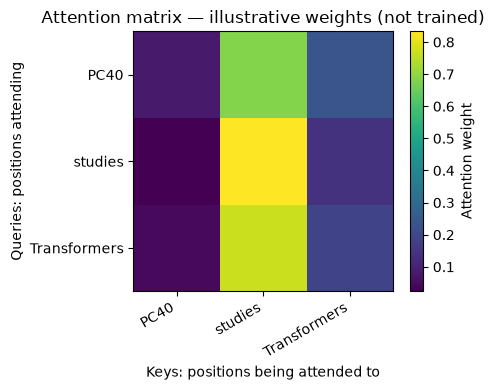

Row sums (must be 1): [1.0, 1.0, 1.0]


In [7]:
weights = torch.softmax((Q @ K.transpose(-2, -1)) / math.sqrt(d_head), dim=-1)
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(weights[0].detach().numpy(), aspect='equal')
ax.set_xticks(range(L), words, rotation=30, ha='right')
ax.set_yticks(range(L), words)
ax.set_xlabel('Keys: positions being attended to')
ax.set_ylabel('Queries: positions attending')
ax.set_title('Attention matrix — illustrative weights (not trained)')
fig.colorbar(im, ax=ax, label='Attention weight')
plt.tight_layout()
plt.show()
print('Row sums (must be 1):', weights[0].sum(dim=-1).tolist())

**Q4.** For $L$ tokens and one head the score matrix is `[L,L]` (here `[B,L,L]` with the batch axis). Softmax normalizes the **last** axis, the key axis, so each query row becomes a probability distribution over the keys it may attend to. Normalizing all $L^2$ entries together would couple rows that are independent: the output of position $i$ would then depend on how large the scores of position $j$ happen to be, and a weighted average of Values for one position would no longer sum to one.

**Q5.** No. The rows are independent of each other, but inside one row the work is not fully independent: the row maximum and the sum of exponentials are **reductions** over all $L$ entries, and no entry can be normalized before the whole sum exists. A Softmax row is therefore parallel in its elementwise exponentials and serial at its two reduction points.

**PC40 question.** For $L=128$ one head needs $128^2=16\,384$ Query–Key dot products. All of them are independent — each reads one query row and one key row and writes one distinct score entry — so none of them has to wait for another. Creating one OS thread per dot product would still be inefficient: each dot product here is 64–128 multiply-adds, a few hundred nanoseconds, while creating and scheduling a thread costs on the order of tens of microseconds, so the overhead would exceed the work by two orders of magnitude, and 16 384 runnable threads on 16 CPUs would only add scheduling and cache pressure. The useful decomposition groups many dot products into one task, which is exactly what a blocked matrix multiplication does. A causal mask removes the entries above the diagonal from contributing, leaving $L(L+1)/2 = 8\,256$ useful scores, but a dense implementation still computes all 16 384 and then masks them.

### Checkpoint — Synthesis 1/4: The Transformer computation

Chain: `text → token IDs → embedding lookup → X → Q=XW_Q, K=XW_K, V=XW_V → S=QK^T/√d_k → row-wise Softmax → A → O=AV`.

Worked example, last token `Transformers`: $q_T=(2,0)$, $q_TK^{\mathsf T}=[0,4,2]$, weights $[0.045,0.768,0.187]$, output $o_T\approx(0.139,1.723)$.

Shapes for one head: scores $[L,L]$, output $[L,d_v]$. One independent operation: every score entry $S_{ij}$ (distinct output location, read-only inputs). One reduction: the per-row max and sum inside Softmax.

## 3 — Parallelize the Transformer (55 min)

### Task 3.1 — Multi-head attention = independent tasks

With $B$ sequences, $H$ heads, $L$ positions and head width $d_h$, $Q,K,V$ are stored as `[B,H,L,d_h]`.

Two versions of the **same per-head algorithm** are compared:

- a serial loop over the $H$ heads (reference);
- the same $H$ head tasks submitted to a persistent `ThreadPoolExecutor` with $p$ workers.

Intra-op stays at 1 for this experiment, so the only parallelism measured is the explicit task-level one.

**TODO 3.1** is implemented below: one task per head, head order preserved, result stacked back to `[B,H,L,D]`.

In [8]:
B_bench, H, L_bench, D = 2, 4, 192, 64
q_bench = torch.randn(B_bench, H, L_bench, D)
k_bench = torch.randn_like(q_bench)
v_bench = torch.randn_like(q_bench)


def serial_heads(q, k, v):
    '''Reference: execute H independent heads in a serial Python loop.'''
    return torch.stack([attention_dense(q[:, h], k[:, h], v[:, h])
                        for h in range(q.shape[1])], dim=1)


def parallel_heads(q, k, v, pool):
    '''TODO 3.1 — dispatch the independent attention heads to an existing pool.

    Ownership: task h reads only the slices q[:, h], k[:, h], v[:, h] of the
    shared read-only input tensors and produces one private output tensor.
    No two tasks write the same location, so no lock is needed; the only
    synchronization is the implicit join inside pool.map, after which the
    main thread stacks the H results back along the head axis.
    '''
    def one_head(h):
        return attention_dense(q[:, h], k[:, h], v[:, h])

    # pool.map preserves the order of the input iterable, so head order is kept.
    return torch.stack(list(pool.map(one_head, range(q.shape[1]))), dim=1)

In [9]:
with ThreadPoolExecutor(max_workers=2) as pool:
    out_parallel = parallel_heads(q_bench, k_bench, v_bench, pool)
assert out_parallel.shape == (B_bench, H, L_bench, D)
assert torch.allclose(out_parallel, serial_heads(q_bench, k_bench, v_bench), atol=1e-5)
max_error_heads = (out_parallel - serial_heads(q_bench, k_bench, v_bench)).abs().max().item()
print(f'PASS TODO 3.1: parallel output equals serial output; maximum error: {max_error_heads:.3g}')

PASS TODO 3.1: parallel output equals serial output; maximum error: 2.61e-07


### Task 3.2 — Benchmark *fixed workload*, vary number of workers

The workload is fixed: same shapes, dtype and algorithm. The relative speedup compares the **thread-pool implementation at $p=1$ and $p>1$**; the serial loop is a different implementation and is printed only for reference, never used as $T_1$.

$$S_p^{\mathrm{fixed,rel}} = \frac{T_{\mathrm{pool},1}}{T_{\mathrm{pool},p}},\quad E_p = \frac{S_p}{p}.$$

In [10]:
throttle_before = cpu_throttle_counters()
serial_loop_ms = measure_ms(lambda: serial_heads(q_bench, k_bench, v_bench))
print(f'Serial-loop latency (ms), separate implementation: {serial_loop_ms:.3f}')
explicit_results = []
for p in P_VALUES:
    with ThreadPoolExecutor(max_workers=p) as pool:
        fn = lambda: parallel_heads(q_bench, k_bench, v_bench, pool)
        fn()   # startup excluded; task submission + join included in measurements
        stats = measure_stats_ms(fn, intra_threads=1)
    explicit_results.append((p, stats['median'], stats['min'], stats['max']))
t1_explicit = explicit_results[0][1]
show_rows(['workers', 'median_ms', 'min_ms', 'max_ms', 'fixed_rel_speedup', 'efficiency'],
          [(p, f'{t:.3f}', f'{lo:.3f}', f'{hi:.3f}', f'{t1_explicit/t:.2f}',
            f'{t1_explicit/t/p:.2f}') for p, t, lo, hi in explicit_results])
throttle_after = cpu_throttle_counters()
for key in ('nr_throttled', 'throttled_usec', 'throttled_time'):
    if key in throttle_before and key in throttle_after:
        print('Observed cgroup', key, 'delta:', throttle_after[key] - throttle_before[key])

Serial-loop latency (ms), separate implementation: 0.810


workers | median_ms | min_ms | max_ms | fixed_rel_speedup | efficiency
--------+-----------+--------+--------+-------------------+-----------
1       | 1.920     | 1.708  | 6.097  | 1.00              | 1.00      
2       | 1.047     | 0.739  | 1.641  | 1.83              | 0.92      
4       | 2.148     | 1.702  | 2.679  | 0.89              | 0.22      
Observed cgroup nr_throttled delta: 0
Observed cgroup throttled_usec delta: 0


### Task 3.3 — Internal parallelism in matrix kernels

The same dense attention expression is now evaluated over all heads at once, and the **PyTorch intra-op thread count** is varied instead of the number of Python tasks. The algorithm is identical for every $p$ in this curve, so the ratio is again a fixed-workload relative speedup — of a different implementation, therefore on its own baseline.

`Timer(num_threads=p)` configures the intra-op setting during the measurement. It does not imply that PyTorch keeps exactly $p$ cores busy at every instant.

intra_op_threads | median_ms | min_ms | max_ms | fixed_rel_speedup | efficiency
-----------------+-----------+--------+--------+-------------------+-----------
1                | 0.743     | 0.740  | 0.753  | 1.00              | 1.00      
2                | 0.450     | 0.366  | 2.434  | 1.65              | 0.83      
4                | 0.333     | 0.204  | 1.314  | 2.23              | 0.56      


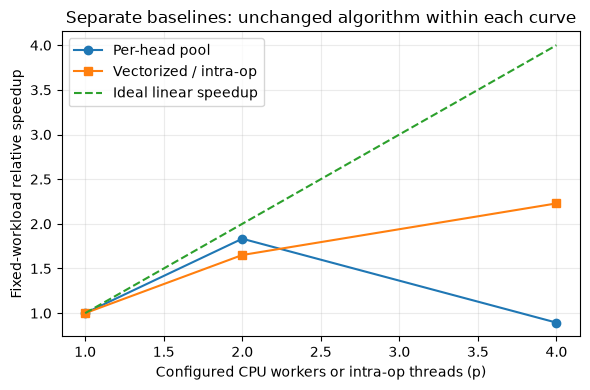

In [11]:
vectorized = lambda: attention_dense(q_bench, k_bench, v_bench)
vectorized_results = []
for p in P_VALUES:
    stats = measure_stats_ms(vectorized, intra_threads=p)
    vectorized_results.append((p, stats['median'], stats['min'], stats['max']))
t1_vect = vectorized_results[0][1]
show_rows(['intra_op_threads', 'median_ms', 'min_ms', 'max_ms',
           'fixed_rel_speedup', 'efficiency'],
          [(p, f'{t:.3f}', f'{lo:.3f}', f'{hi:.3f}', f'{t1_vect/t:.2f}',
            f'{t1_vect/t/p:.2f}') for p, t, lo, hi in vectorized_results])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([p for p, _, _, _ in explicit_results],
        [t1_explicit / t for _, t, _, _ in explicit_results], 'o-', label='Per-head pool')
ax.plot([p for p, _, _, _ in vectorized_results],
        [t1_vect / t for _, t, _, _ in vectorized_results], 's-', label='Vectorized / intra-op')
ax.plot(P_VALUES, P_VALUES, '--', label='Ideal linear speedup')
ax.set_xlabel('Configured CPU workers or intra-op threads (p)')
ax.set_ylabel('Fixed-workload relative speedup')
ax.set_title('Separate baselines: unchanged algorithm within each curve')
ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### Optional challenge — oversubscription

Workers and intra-op threads are combined deliberately. `workers × intra_op_threads` is **not** a count of simultaneously busy cores: the operating system schedules runnable threads, and the product may exceed the allocation.

In [12]:
oversub = []
for workers in (1, 2, 4):
    for intra in (1, 2, 4):
        with ThreadPoolExecutor(max_workers=workers) as pool:
            fn = lambda: parallel_heads(q_bench, k_bench, v_bench, pool)
            fn()
            torch.set_num_threads(intra)
            stats = measure_stats_ms(fn, intra_threads=intra)
            torch.set_num_threads(1)
        oversub.append((workers, intra, workers * intra, stats['median']))
best = min(t for *_, t in oversub)
show_rows(['pool_workers', 'intra_op', 'threads_requested', 'median_ms', 'vs_best'],
          [(w, i, prod, f'{t:.3f}', f'{t/best:.2f}x') for w, i, prod, t in oversub])
print(f'Best configuration: {min(oversub, key=lambda r: r[3])[:3]} at {best:.3f} ms')

pool_workers | intra_op | threads_requested | median_ms | vs_best
-------------+----------+-------------------+-----------+--------
1            | 1        | 1                 | 0.957     | 1.00x  
1            | 2        | 2                 | 1.896     | 1.98x  
1            | 4        | 4                 | 2.289     | 2.39x  
2            | 1        | 2                 | 1.008     | 1.05x  
2            | 2        | 4                 | 1.098     | 1.15x  
2            | 4        | 8                 | 1.158     | 1.21x  
4            | 1        | 4                 | 1.186     | 1.24x  
4            | 2        | 8                 | 1.588     | 1.66x  
4            | 4        | 16                | 1.752     | 1.83x  
Best configuration: (1, 1, 1) at 0.957 ms


**Q6.** The scaling of the per-head pool is limited by granularity and by the amount of work available. Only $H=4$ head tasks exist, so $p=4$ is the largest useful worker count and any load imbalance costs a whole task; each task is a few matrix multiplications of a few hundred microseconds, which is large enough to amortize a `pool.map` dispatch but not large enough to hide it entirely. Task creation itself is excluded — the pool is persistent and warmed before timing — but submission, future bookkeeping and the join remain inside the measured region, and they grow with $p$. The pool is genuinely used: `parallel_heads` submits through `pool.map`, and the correctness test above compares its output against the serial loop. On a shared or quota-limited VM a cgroup budget would cap real parallelism further; the throttling deltas printed above record whether that happened here.

**Q7.** The two curves must be computed within their own algorithm because they are not the same program. The vectorized version issues one batched matmul over all $B\cdot H$ matrices, so PyTorch's own intra-op threads split that single operation; the pool version issues $H$ separate smaller operations from Python. Dividing one implementation's time by another's would measure the change of algorithm and the change of thread count at the same time, and neither factor could be attributed. Which one is faster at $p=1$ is reported in the tables above and discussed in the synthesis.

### Checkpoint — Synthesis 2/4: The execution environment

Recorded from the inventory cell: visible logical CPUs, process affinity, CPU-equivalent quota (or *not exposed*), memory limit, Python/PyTorch versions and intra-op setting. A cgroup quota is a CPU-*time* budget per scheduler period, not a reservation of cores: it says how much CPU time may be consumed, not which or how many CPUs serve it, and it is unrelated to a Colab account-level session or usage limit, which no kernel file exposes. The defensible values of $p$ are those at or below the printed allocation.

## 4 — Optimize & Benchmark (45 min)

### Task 4.1 — Fair comparison of *different* implementations

At a fixed intra-op thread count, three implementations of the same mathematics are compared: the per-head serial loop, the vectorized batched attention, and PyTorch SDPA. They agree numerically but differ in algorithm and kernel, so the ratio below is an **optimization ratio, not a parallel speedup**.

In [13]:
impls = {
    'serial head loop': lambda: serial_heads(q_bench, k_bench, v_bench),
    'vectorized attention': lambda: attention_dense(q_bench, k_bench, v_bench),
    'PyTorch SDPA': lambda: F.scaled_dot_product_attention(q_bench, k_bench, v_bench, dropout_p=0.0),
}
with torch.inference_mode():
    outputs = {name: fn() for name, fn in impls.items()}
for name, out in outputs.items():
    assert torch.allclose(out, outputs['serial head loop'], atol=2e-4, rtol=2e-4), name
max_impl_error = max((out - outputs['serial head loop']).abs().max().item()
                     for out in outputs.values())
print(f'All three implementations agree; maximum deviation: {max_impl_error:.3g}')

compare_times = {name: measure_ms(fn, intra_threads=1) for name, fn in impls.items()}
base = compare_times['serial head loop']
show_rows(['implementation', 'time_ms (1 intra-op thread)', 'loop / implementation'],
          [(name, f'{t:.3f}', f'{base/t:.2f}x') for name, t in compare_times.items()])

All three implementations agree; maximum deviation: 5.36e-07


implementation       | time_ms (1 intra-op thread) | loop / implementation
---------------------+-----------------------------+----------------------
serial head loop     | 0.764                       | 1.00x                
vectorized attention | 0.741                       | 1.03x                
PyTorch SDPA         | 0.656                       | 1.17x                


**Q8.** Yes, a well optimized single-thread kernel can beat a naive multi-thread one. First, the arithmetic itself can differ by a large constant: a blocked, vectorized GEMM keeps its operands in registers and cache and issues wide SIMD fused multiply-adds, while a naive implementation re-reads the same data from memory and leaves most of the vector units idle — more cores do not help a kernel that is waiting on memory. Second, a fused kernel such as SDPA need not materialize the whole $L\times L$ score matrix, so it moves far fewer bytes, whereas the naive version writes the scores, reads them back for Softmax, writes the weights and reads them again; on a memory-bandwidth-bound problem adding threads adds contention rather than throughput. `loop_time / SDPA_time` cannot be called $S_p^{\mathrm{fixed,rel}}$ because the two sides run different algorithms at the same thread count: the definition requires one unchanged implementation with only $p$ varying.

### Task 4.2 — Memory and computation with longer sequences

For dense, explicitly materialized self-attention the score matrix is `[B,H,L,L]`, that is $4BHL^2$ bytes in float32, and the two matrix multiplications cost $O(BHL^2d_h)$. This is the storage of **one** materialized score matrix, a lower bound on the intermediate memory: the explicit implementation also holds the Softmax weights and the output.

L   | one_score_matrix_MiB | time_ms | time vs previous L
----+----------------------+---------+-------------------
64  | 0.12                 | 0.092   | -                 
128 | 0.50                 | 0.333   | 3.62x             
256 | 2.00                 | 1.322   | 3.97x             
512 | 8.00                 | 12.415  | 9.39x             


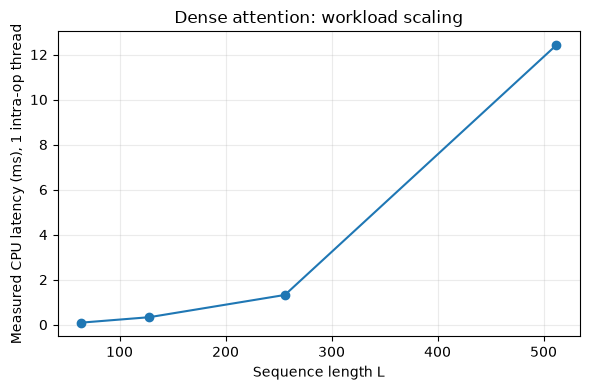

In [14]:
B_mem, H_mem, D_mem = 2, 4, 64
lengths = [64, 128, 256, 512]
mem_results = []
for seq_len in lengths:
    q = torch.randn(B_mem, H_mem, seq_len, D_mem)
    k = torch.randn_like(q)
    v = torch.randn_like(q)
    fn = lambda q=q, k=k, v=v: attention_dense(q, k, v)
    t = measure_ms(fn, intra_threads=1, min_run_time=0.08)
    score_mib = B_mem * H_mem * seq_len * seq_len * 4 / (1024**2)
    mem_results.append((seq_len, score_mib, t))
rows = []
for i, (length, mem, t) in enumerate(mem_results):
    ratio = '-' if i == 0 else f'{t/mem_results[i-1][2]:.2f}x'
    rows.append((length, f'{mem:.2f}', f'{t:.3f}', ratio))
show_rows(['L', 'one_score_matrix_MiB', 'time_ms', 'time vs previous L'], rows)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([x[0] for x in mem_results], [x[2] for x in mem_results], 'o-')
ax.set_xlabel('Sequence length L')
ax.set_ylabel('Measured CPU latency (ms), 1 intra-op thread')
ax.set_title('Dense attention: workload scaling')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**Q9.** When $L$ doubles at fixed $B,H,d_h$, the number of score entries is multiplied by exactly 4, and so is the nominal arithmetic of both matrix multiplications. The measured time is not multiplied by exactly 4. At small $L$ a fixed overhead per operation — Python dispatch, allocation of the intermediate tensors, kernel launch — is a visible fraction of the total, so the first doublings grow by less than 4. As $L$ grows the score matrix stops fitting in cache: at $L=512$ one float32 score matrix is 8 MiB, and with the weights and output the working set exceeds the last-level cache, so the kernel starts paying main-memory traffic and the growth can exceed 4. The matrix shapes also change with $L$, which changes how well the GEMM blocking fits.

**Q10.** Timing alone cannot separate the two regimes, so vary the two costs independently. Keeping $L$ fixed and increasing $d_h$ multiplies the arithmetic ($O(L^2d_h)$) while leaving the score matrix size ($O(L^2)$) unchanged; if the time barely moves, the kernel is limited by the score traffic rather than by arithmetic. Conversely, keeping the total element count fixed while reshaping the problem changes the footprint at constant work. The measured arithmetic intensity — FLOPs divided by bytes moved — can then be placed against the machine's ratio of peak FLOP/s to memory bandwidth. Where hardware counters are accessible, `perf stat` on cache misses and memory-bus cycles gives direct evidence instead of an inference from wall-clock time.

### Why the per-head pool scales badly — three measurements

The thread-pool results above are sublinear. `ceiling_lab4.py` measures the reason rather than guessing it:

1. **The pool and the GIL are not the barrier.** The same `ThreadPoolExecutor`, running 16 large
   compute-bound tasks on 8 identical cores, reaches $S_8 = 7.49$ ($E_8 = 0.94$). So the tasks really do
   run at the same time and PyTorch does release the GIL inside its kernels. A pure-Python task in the
   same pool gives $0.32\times$ — that is what a GIL-bound workload looks like.
2. **The cores are not equal.** This CPU is hybrid: a P-core gives 80.2 GFLOP/s, an E-core 60.3, an
   LP-E core 30.3. A join waits for the slowest worker, so the same pool at $p=4$ gives $S_4 = 2.60$ on
   four identical P-cores but only 1.98 when the scheduler may use all 16 CPUs.
3. **The tasks are small and too few.** One head is 1–3 ms, while `pool.map` alone costs 207 µs at
   $p=1$ and 518 µs at $p=16$; and with $H=4$ there are only four tasks, so $p>4$ adds workers that own
   nothing.

### Checkpoint — Synthesis 3/4: Multicore execution and performance

Both fixed-workload curves are produced above, each against its own $T_1$, with median and min–max spread. Ownership is exclusive per head; the only synchronization is the join inside `pool.map`; intra-op is pinned to 1 for the explicit series and varied only in the vectorized series. The measured limits are reported in the synthesis, separately from the optimization ratios of Task 4.1.

## 5 — GenAI Challenge: Prefill vs Decoding (20 min)

Prefill processes the whole prompt at once: all query positions are available, so dense causal attention costs $O(L^2d_h)$ per head and is fully parallel across positions. One cached decoding step compares a single new query against up to $L$ cached keys, costing $O(Ld_h)$ per head, but the step cannot start before the previous token exists.

### Task 5.1 — Same result, different computation

In [15]:
B_gen, H_gen, length_gen, D_gen = 1, 2, 16, 32
q = torch.randn(B_gen, H_gen, length_gen, D_gen)
k = torch.randn_like(q)
v = torch.randn_like(q)
errors = []
for t in range(1, length_gen + 1):
    # Recompute full causal attention on the prefix [0:t].
    whole = attention_dense(q[:, :, :t], k[:, :, :t], v[:, :, :t], causal=True)
    last_from_full = whole[:, :, -1:, :]
    # Query at the last position attends to all keys already available.
    last_from_cached = attention_dense(q[:, :, t-1:t], k[:, :, :t], v[:, :, :t], causal=False)
    errors.append((last_from_full - last_from_cached).abs().max().item())
print('Max difference (full-prefix vs single-query attention):', max(errors))
assert max(errors) < 1e-5
print('A KV cache is therefore exact, not an approximation: it only avoids recomputation.')

Max difference (full-prefix vs single-query attention): 4.76837158203125e-07
A KV cache is therefore exact, not an approximation: it only avoids recomputation.


In [16]:
# Cost of the two regimes, same head width, measured on this machine.
prefill_ms = measure_ms(lambda: attention_dense(q, k, v, causal=True), intra_threads=1)
step_ms = measure_ms(lambda: attention_dense(q[:, :, -1:], k, v, causal=False), intra_threads=1)
print(f'Prefill of {length_gen} positions : {prefill_ms:.4f} ms')
print(f'One cached decoding step   : {step_ms:.4f} ms')
print(f'{length_gen} sequential steps      : {length_gen*step_ms:.4f} ms '
      f'({length_gen*step_ms/prefill_ms:.2f}x the prefill of the same length)')

Prefill of 16 positions : 0.0116 ms
One cached decoding step   : 0.0082 ms
16 sequential steps      : 0.1312 ms (11.36x the prefill of the same length)


### Task 5.2 — Illustrative token-by-token generation

This tiny, **untrained** random model returns token IDs and shows the dependency: the input to the next step contains the token produced at the current step. Its output is not meaningful language.

In [17]:
toy_vocabulary = ['PC40', 'studies', 'parallel', 'computing', 'Transformer', 'CPU', '.', '<eos>']
toy_d = 32
emb = torch.randn(len(toy_vocabulary), toy_d) * 0.2
Wq_toy, Wk_toy, Wv_toy, Wout_toy = [torch.randn(toy_d, toy_d) / math.sqrt(toy_d) for _ in range(4)]
pos_toy = torch.randn(32, toy_d) * 0.02


def next_token(prefix_ids):
    x = emb[torch.tensor(prefix_ids)] + pos_toy[:len(prefix_ids)]
    q_toy, k_toy, v_toy = x @ Wq_toy, x @ Wk_toy, x @ Wv_toy
    # Causal attention: earlier tokens cannot attend to future ones.
    y = attention_dense(q_toy.unsqueeze(0), k_toy.unsqueeze(0),
                        v_toy.unsqueeze(0), causal=True)
    last = y[0, -1]
    logits = last @ Wout_toy @ emb.transpose(0, 1)
    return int(logits.argmax())

prefix = [0, 1]   # PC40 studies
for step in range(4):
    predicted = next_token(prefix)
    prefix.append(predicted)   # dependent next step
    print(f'step {step+1}:', ' '.join(toy_vocabulary[i] for i in prefix))

step 1: PC40 studies studies
step 2: PC40 studies studies studies
step 3: PC40 studies studies studies studies
step 4: PC40 studies studies studies studies studies


**Q11.** During prefill every query of the prompt already exists, because the prompt is given. The causal mask only removes score entries; it does not make a position wait for another position, so all $L$ rows of the score matrix can be computed at the same time. In autoregressive decoding the query of step $t+1$ is built from the embedding of the token produced at step $t$, which is itself the arg-max of the step-$t$ output. That value does not exist before step $t$ finishes, so the four next tokens form a chain of four dependent steps: the standard algorithm can parallelize *inside* a step but cannot overlap the steps.

**Q12.** (a) Per-token latency is the time of one decoding step and sets how fast the text appears once it has started. (b) End-to-end latency is the prefill plus the sum of all per-token latencies, so it is what a user waits for a complete answer. (c) Throughput is generated tokens per second summed over all concurrent requests. One interactive user cares about (a) and (b): the stream must not stall. A server operator cares about (c), because the hardware is paid per unit of time and must be kept busy across many users.

**Q13.** Batch different users' sequences together. The dependency is *within* one sequence, not between sequences, so the step-$t$ decoding of many independent requests can be issued as one larger batched matrix multiplication. That turns many small, memory-bound, latency-dominated operations into one operation with much better arithmetic intensity, raising tokens/s per machine while the per-sequence chain of steps stays exactly as long. Continuous batching, where finished sequences are replaced by new ones at each step, is the production form of this idea.

**Q14.** No. `cpu.max` is a kernel cgroup file: it states a CPU-time budget per scheduler period for this container, enforced locally by the CFS scheduler. The Colab account-level allowance and the remaining session lifetime live in Google's platform accounting, are not exported into the container's filesystem, and can terminate a session that is well inside its `cpu.max` budget. The two limits answer different questions: how fast the process may consume CPU, versus how long the platform will keep providing it.

### Checkpoint — Synthesis 4/4: Portability and reproducibility

Inside one speedup series the program version, the shapes $B,H,L,d_h$, the dtype, the random seed, the warm-up and repetition protocol, the timing scope and the intra-op setting all stay fixed, and $T_1$ and $T_p$ come from the same machine. What changes between a Colab VM, this local node and a mesocentre node is the CPU model and frequency, the core count and topology, the cache sizes and memory bandwidth, the cgroup quota, and the amount of competing load. Those change the baseline $T_1$ itself, so a curve from one machine cannot be continued with points from another: cross-machine results are reported as separate curves with their own hardware record.

## 6 — Final synthesis and oral evaluation

Deliverables: this notebook with both TODO functions implemented and all tests executed, plus the two-page guided synthesis assembled from the four checkpoints.